In [39]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from astropy.io import fits
from pathlib import Path

%matplotlib inline

mpl.rcParams.update({
    # Figure
    "figure.figsize":   (4, 3),
    "figure.dpi":       200,

    # Fonts
    "font.family":      "serif",
    "font.serif":       ["Times New Roman", "Palatino", "serif"],
    "font.size":        15,

    # Axes
    "axes.titlesize":   16,
    "axes.labelsize":   14,
    "axes.linewidth":   1.0,
    "axes.grid":        False,
    "axes.grid.axis":   "both",
    "axes.grid.which":  "both",
    "axes.prop_cycle":  mpl.cycler(
                            "color",
                            ["#1f77b4","#ff7f0e","#2ca02c",
                             "#d62728","#9467bd","#8c564b"]
                        ),

    # Grid
    "grid.linestyle":   "--",
    "grid.linewidth":   0.8,
    "grid.alpha":       0.7,

    # Lines & markers
    "lines.linewidth":  1.0,
    "lines.markersize": 6,

    # Ticks
    "xtick.direction":  "in",
    "ytick.direction":  "in",
    "xtick.labelsize":  11,
    "ytick.labelsize":  11,
    "xtick.major.size": 5,
    "ytick.major.size": 5,
    "xtick.minor.size": 3,
    "ytick.minor.size": 3,

    # Legend
    "legend.fontsize":  11,
    "legend.frameon":   False,

    # Image
    "image.cmap":       "viridis",
    "image.origin":		"lower"
})

In [40]:
filename = "L1/20241016/KP.20241016.55598.79_L1.fits"

hdul = fits.open(filename)

hdul.info()

for name in ["GREEN_CAL_FLUX", "GREEN_CAL_WAVE", "GREEN_SCI_WAVE1"]:
    print("\n", name)
    print(repr(hdul[name].header))

print('\n')
print(hdul['RECEIPT'].data)

Filename: L1/20241016/KP.20241016.55598.79_L1.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    1024   ()      
  1  RECEIPT       1 BinTableHDU     31   24R x 11C   [26A, 7A, 9A, 1A, 18A, 140A, 53A, 40A, 3A, 40A, 4A]   
  2  CONFIG        1 BinTableHDU     13   0R x 2C   [D, D]   
  3  TELEMETRY     1 BinTableHDU     24   131R x 6C   [11A, 11A, 8A, 8A, 14A, 67A]   
  4  GREEN_SCI_FLUX1    1 ImageHDU        13   (4080, 35)   float64   
  5  GREEN_SCI_FLUX2    1 ImageHDU        13   (4080, 35)   float64   
  6  GREEN_SCI_FLUX3    1 ImageHDU        13   (4080, 35)   float64   
  7  GREEN_SKY_FLUX    1 ImageHDU        13   (4080, 35)   float64   
  8  GREEN_CAL_FLUX    1 ImageHDU        13   (4080, 35)   float64   
  9  GREEN_SCI_VAR1    1 ImageHDU         8   (4080, 35)   float64   
 10  GREEN_SCI_VAR2    1 ImageHDU         8   (4080, 35)   float64   
 11  GREEN_SCI_VAR3    1 ImageHDU         8   (4080, 35)   float64   
 12  GREEN_SKY_V

## Notes For the Code Below

This is the site for the data that Dr. Mann shared with me: https://www2.keck.hawaii.edu/inst/kpf/
In it, it says that the scope "covers a wavelength range of 445 nm to 870 nm"

In the document it says that a Calcium H&K spectrum is also taken, but getting this data from the fits file yields that it is just empty? (See graphing section in the code)
Dr. Mann said that the wavelengths are not identical between fibers and exposures? I assume this means we need to somehow find the Ca H&K spectrum, use that to calibrate, then match the fiber data before median stacking.
He also said the "Simplest [way] is to interpolate to match before stacking, but consider what uncertainties that creates"


Y-axis is the order of the grating, not spatial information. We should analyze each order separately?
Green data has 35 orders, red data only 32. I say we only looks at orders 0-32 and leave out the last few of green so we can use all data

The below data is not sky subtracted. Reason being is that "the throughput of the sky fiber is slightly different. You might find you need to ’scale’ to match as part of the subtraction, or combine many sky spectra to get proper SNR."
I'm not sure how we can tell what the true sky level should be and what ratio to scale it by

In [41]:
## Given a folder path, opens each file in the folder and extracts the flux and wavelength data for both red and green channels
#	Returns a list of the green flux, red flux, green wavelength, red wavelength with each item in each being a different observation
def _open_files(folder_path):
	green_sci_flux = []
	red_sci_flux = []
	green_sci_wave = []
	red_sci_wave = []

	g_calibration_flux = []
	g_calibration_wave = []
	r_calibration_flux = []
	r_calibration_wave = []

	for file in folder_path.iterdir():
		with fits.open(file) as hdu:

			flux = hdu['GREEN_SCI_FLUX1'].data
			flux2 = hdu['GREEN_SCI_FLUX2'].data
			flux3 = hdu['GREEN_SCI_FLUX3'].data
			green_sci_flux.append(flux + flux2 + flux3) # Emailed Dr. Mann and he said its best to sum the 3 fibers


			flux = hdu['RED_SCI_FLUX1'].data
			flux2 = hdu['RED_SCI_FLUX2'].data
			flux3 = hdu['RED_SCI_FLUX3'].data
			red_sci_flux.append(flux + flux2 + flux3) # Emailed Dr. Mann and he said its best to sum the 3 fibers

			wave = hdu['GREEN_SCI_WAVE1'].data
			wave2 = hdu['GREEN_SCI_WAVE2'].data
			wave3 = hdu['GREEN_SCI_WAVE3'].data
			green_sci_wave.append(wave)

			wave = hdu['RED_SCI_WAVE1'].data
			wave2 = hdu['RED_SCI_WAVE2'].data
			wave3 = hdu['RED_SCI_WAVE3'].data
			red_sci_wave.append(wave)


			## Extracting calibration data
			g_cal_flux = hdu['GREEN_CAL_FLUX'].data
			g_cal_wave = hdu['GREEN_CAL_WAVE'].data
			g_calibration_flux.append(g_cal_flux)
			g_calibration_wave.append(g_cal_wave)

			r_cal_flux = hdu['RED_CAL_FLUX'].data
			r_cal_wave = hdu['RED_CAL_WAVE'].data
			r_calibration_flux.append(r_cal_flux)
			r_calibration_wave.append(r_cal_wave)

	return green_sci_flux, red_sci_flux, green_sci_wave, red_sci_wave, g_calibration_flux, g_calibration_wave, r_calibration_flux, r_calibration_wave




## Median stacks an array of data
def _median_stack(data_array):
	return np.median(data_array, axis=0)




## Notes

I extract the calibration data and graph it below. I haven't used it at all but there's still some more that needs to go into processing this data before it's all median stacked. This being using the calibration data (whatever it is), subtracting the sky, and wavelength calibration (if needed).
 
I found this paper that talks about the reduction steps in pretty good detail for the exact type of scope we're looking at: https://iopscience.iop.org/article/10.3847/1538-3881/ae71b9/meta#ajae71b9s3-3.

There's also another step we could do called 'Blaze Correction' that would help fix those humps you can see in the data (see the graphs with all the colors). From what I can find we need a flat field for this and it doesn't look like we have one, or I don't know where to find it. 

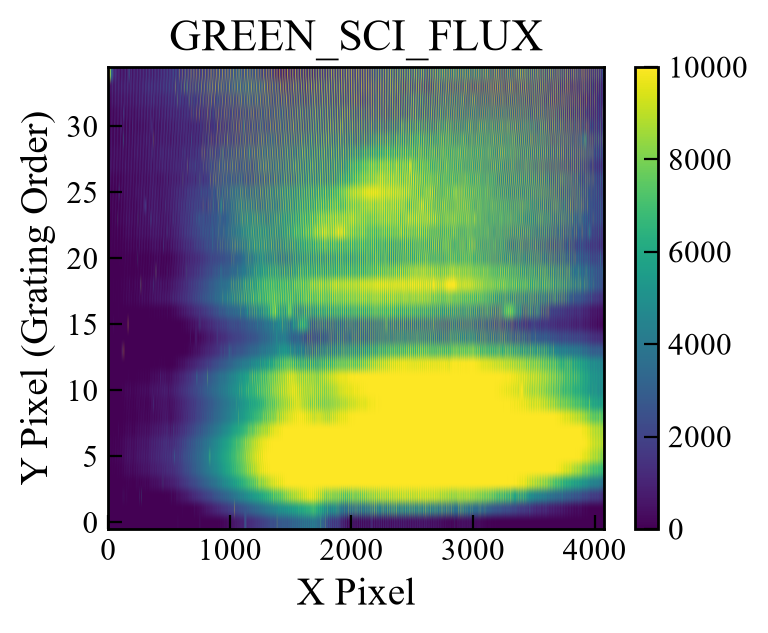

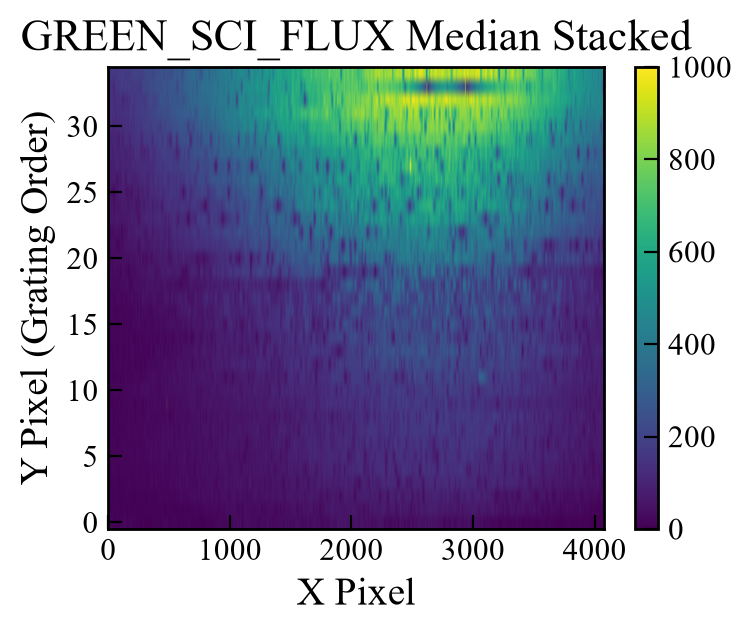

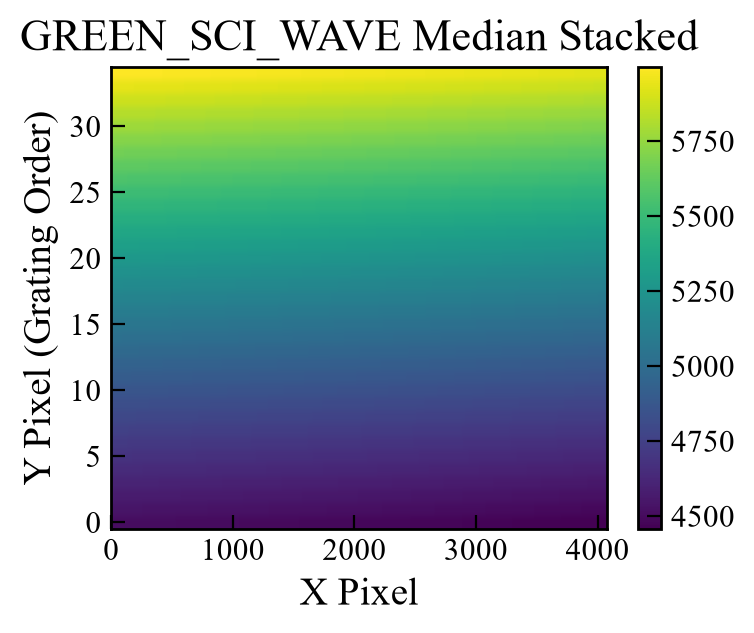

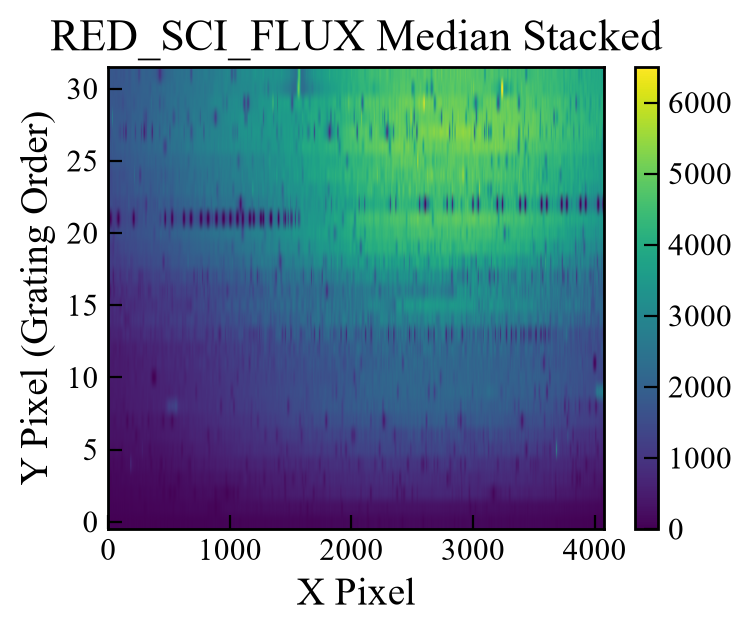

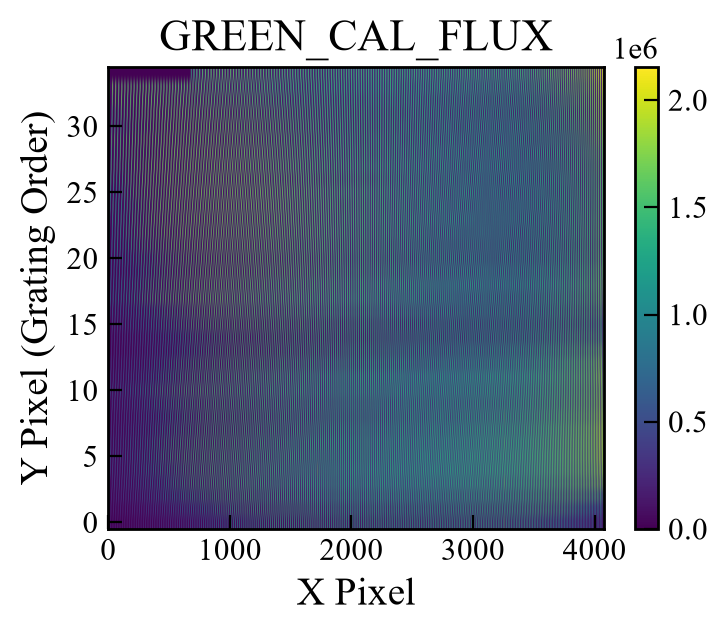

In [42]:
### Open folders
night_1_folder = Path('L1/20241016')
night_2_folder = Path('L1/20250125')



## Extracting data for night 1 (each index of each list is a different observation in the same night)
g_flux_list, r_flux_list, g_wave_list, r_wave_list, g_cal_flux_list, g_cal_wave_list, r_cal_flux_list, r_cal_wave_list = _open_files(night_1_folder)


## Median stacking across all observations
g_flux_med = _median_stack(np.array(g_flux_list))
r_flux_med = _median_stack(np.array(r_flux_list))

g_wave_med = _median_stack(np.array(g_wave_list))
r_wave_med = _median_stack(np.array(r_wave_list))


## Show data (I'm a big visual guy)
plt.imshow(g_flux_list[0], vmin=0, vmax=10000, aspect='auto')
plt.title('GREEN_SCI_FLUX')
plt.xlabel('X Pixel')
plt.ylabel('Y Pixel (Grating Order)')
plt.colorbar()
plt.show()

plt.imshow(g_flux_med, vmin=0, vmax=1000, aspect='auto')
plt.title('GREEN_SCI_FLUX Median Stacked')
plt.xlabel('X Pixel')
plt.ylabel('Y Pixel (Grating Order)')
plt.colorbar()
plt.show()

plt.imshow(g_wave_med, aspect='auto')
plt.title('GREEN_SCI_WAVE Median Stacked')
plt.xlabel('X Pixel')
plt.ylabel('Y Pixel (Grating Order)')
plt.colorbar()
plt.show()

plt.imshow(r_flux_med, vmin=0, vmax=6500, aspect='auto')
plt.title('RED_SCI_FLUX Median Stacked')
plt.xlabel('X Pixel')
plt.ylabel('Y Pixel (Grating Order)')
plt.colorbar()
plt.show()

plt.imshow(g_cal_flux_list[0], aspect='auto')
plt.title('GREEN_CAL_FLUX')
plt.xlabel('X Pixel')
plt.ylabel('Y Pixel (Grating Order)')
plt.colorbar()
plt.show()

## Order Grapher

Graphs the data at a given order

### Notes

There seems to be less flux at the edges of each order, which makes these "hump" patterns for each order. Is there a way to normalize the value at each order or find the average and fit around that?

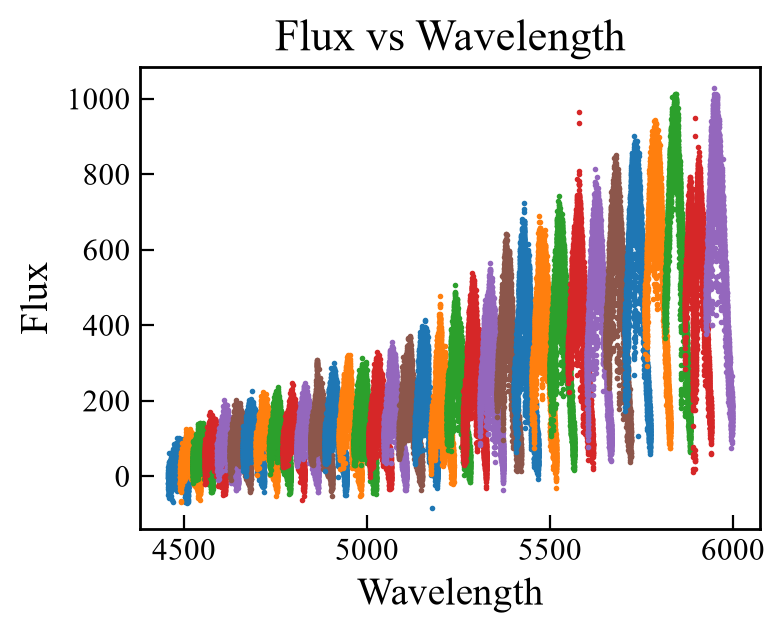

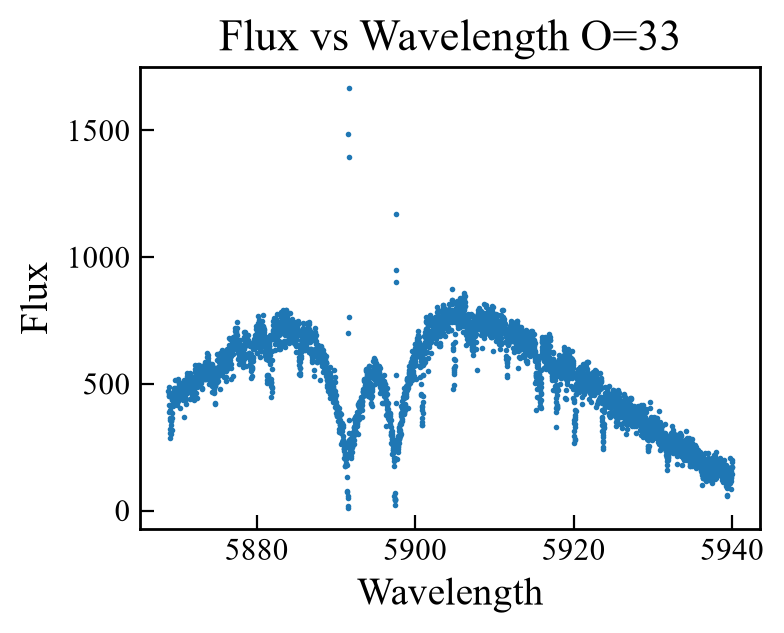

In [ ]:
def _order_extraction(flux_im, wave_im, order):
	flux_order = flux_im[order,:]
	wave_order = wave_im[order,:]

	return flux_order, wave_order


def _remove_outliers(flux, wave, mean, std):
	lower = mean - 3*std
	upper = mean + 3*std
	mask = (lower < flux) & (flux < upper)
	return flux[mask], wave[mask]


def _plot_all_orders(flux_im, wave_im, o_min, o_max):
	for i in range(len(flux_im)):
		for order in range(o_min, o_max):
			flux, wave = _order_extraction(flux_im[i], wave_im[i], order)
			mean = np.mean(flux)
			std = np.std(flux)
			flux_rej, wave_rej = _remove_outliers(flux, wave, mean, std)
			plt.scatter(wave_rej, flux_rej, s=1)

	plt.title('Flux vs Wavelength')
	plt.xlabel('Wavelength')
	plt.ylabel('Flux')
	plt.show()


_plot_all_orders([g_flux_med], [g_wave_med], 0, 35) ## Takes a list to also include red data later on


## No outlier removal
flux1, wave1 = _order_extraction(g_flux_med, g_wave_med, 33)
plt.scatter(wave1, flux1, s=1)
plt.title('Flux vs Wavelength O=33')
plt.xlabel('Wavelength')
plt.ylabel('Flux')
plt.show()